# Applications: which purées need a closer look?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/04_Applications/notebooks/TD3_strawberry_student.ipynb)

In Foundations and Evaluation, models chose between Strawberry and
NON-Strawberry. Here we use the same eight features to ask a different
question: is a measurement unusual compared with the labelled
Strawberry training samples? The output is a flag for laboratory review.

An outlier is an unusual observation relative to a reference group.
A flag means check this sample, not this product is adulterated.

All code is supplied. Run the cells from top to bottom with their ▶ buttons.
Read the explanation above each cell and inspect its output. To answer a
question, double-click its Your answer text cell and write in words.

Click Open in Colab above to start this notebook. Use the standard CPU runtime.

## 1. Look at the measurements

Each sample is one recorded measurement of a fruit purée. Its infrared
spectrum contains 235 signal values measured at different wavenumbers.
A wavenumber identifies a position along the infrared spectrum.

A feature is a number describing a sample. For now, each measured signal
at a particular wavenumber is one feature: 235 features per sample.
The recorded label gives the known class and is kept separate from the features.

Strawberry is one class. NON-Strawberry includes other fruit purées and
adulterated strawberry mixtures. The file does not identify the particular
adulterant or its amount for each sample.

The first cell loads the tools: `pd` works with tables and `plt` draws plots.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest

Read the public data file. Its first row contains sample labels, so
`header=None` keeps that row in the table. The fixed address selects the
same version of the source file throughout the strawberry practicals.

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/zwbben/SpectroscopyData/"
    "4db9b8168fac1185973d1e7888d51f7f33f94857/MIR_Fruit_purees.csv"
)
raw_data = pd.read_csv(DATA_URL, header=None)

Here is the table as it was read. Row 0 gives the sample labels. Column 0
gives the wavenumbers, starting below the word Wavenumbers. Each remaining
column contains one sample's spectrum. The table has 983 sample columns.
Only the first and last parts of this large table are displayed.

In [3]:
raw_data

,0,1,2,3,4,5,6,7,8,9,...,974,975,976,977,978,979,980,981,982,983
0,Wavenumbers,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,...,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry,NON-Strawberry
1,899.327,0.002805507,0.00263738,0.002415868,0.00234529,0.002302508,0.002513791,0.002105496,0.002018384,0.002153632,...,0.002539315,0.002568574,0.002723227,0.002542207,0.00262688,0.002631082,0.002730378,0.002712845,0.002696845,0.002789428
2,903.187,0.002731944,0.002638345,0.002479677,0.002291981,0.00234218,0.002488288,0.002078167,0.0019987,0.002165058,...,0.002507276,0.002568594,0.002714211,0.002538884,0.002629394,0.002650873,0.002838751,0.0027786,0.00290547,0.003039869
3,907.047,0.00266115,0.002651382,0.002510657,0.002248641,0.00234953,0.00247745,0.002077299,0.001944556,0.002191274,...,0.002482726,0.002541337,0.002739762,0.002574314,0.002618641,0.002696092,0.002999267,0.002877433,0.003277223,0.003358926
4,910.907,0.00265707,0.002757381,0.002611341,0.002303143,0.002419224,0.002542069,0.002154436,0.001963826,0.002274862,...,0.002562686,0.002598623,0.002860805,0.002663535,0.002713847,0.002809383,0.003258967,0.003084947,0.003711203,0.003796026
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
231,1787.124,8.70401E-05,-5.50734E-06,6.22218E-05,7.52099E-05,9.87553E-05,5.40501E-05,6.37965E-05,0.000101614,8.11771E-05,...,4.1971E-06,8.43141E-06,8.41589E-06,5.40847E-06,1.21E-05,-1.26769E-06,-7.71062E-07,6.59038E-06,-9.43563E-06,-2.02171E-05
232,1790.984,4.58481E-05,1.84089E-06,3.11324E-05,4.29712E-05,5.37301E-05,3.14769E-05,4.30507E-05,6.35453E-05,5.52157E-05,...,6.96074E-06,1.84257E-05,1.02528E-05,6.93735E-06,1.21853E-05,2.9724E-06,2.04995E-07,6.81436E-06,-5.09051E-06,-5.91353E-06
233,1794.844,1.08289E-05,9.65908E-06,8.81474E-06,2.10302E-05,1.97074E-05,1.60126E-05,2.71518E-05,3.76145E-05,3.25956E-05,...,1.43265E-05,1.41472E-05,1.49764E-05,1.29431E-05,9.70352E-06,7.40502E-06,6.58678E-06,1.21564E-05,-2.41264E-06,-5.06714E-06
234,1798.704,9.39817E-06,5.07603E-06,7.15697E-06,7.53529E-06,1.17139E-05,8.13114E-06,1.19344E-05,1.46512E-05,1.35374E-05,...,1.08665E-05,1.1123E-05,1.0027E-05,9.52043E-06,6.39644E-06,7.76824E-06,5.12522E-06,1.28675E-05,1.04989E-06,-1.83347E-06


Separate the labels from the numbers. Because each source column contains
both words and numbers, the values were initially read as text.
`astype(float)` converts the numerical part to numbers, once.

`iloc` selects rows or columns by their position. `.T` swaps rows and
columns so that each row of `spectra` becomes one sample. The last line
uses the wavenumbers to name its columns.

In [4]:
labels = raw_data.iloc[0, 1:]
numeric_data = raw_data.iloc[1:].astype(float)
spectra = numeric_data.iloc[:, 1:].T
spectra.columns = numeric_data.iloc[:, 0]

Two records have exactly the same measurements but opposite labels.
We leave both out because the file cannot tell us which label is right.
`~` means “not”: keep the rows that are not repeated. This leaves 981
spectra: 350 Strawberry and 631 NON-Strawberry.

In [5]:
repeated = spectra.duplicated(keep=False)
spectra = spectra.loc[~repeated]
labels = labels.loc[~repeated]
print("Samples kept:", len(spectra))
print(labels.value_counts())

Samples kept: 981
0
NON-Strawberry    631
Strawberry        350
Name: count, dtype: int64


The measurements now have one sample per row and one wavenumber per column.
Show the first five rows and six measured wavenumbers. Each entry is that
sample's supplied infrared signal at that wavenumber. The row numbers
identify positions in the source file, not physical specimen IDs.

In [6]:
spectra.iloc[:5, :6]

,899.327,903.187,907.047,910.907,914.767,918.627
1,0.002806,0.002732,0.002661,0.002657,0.002699,0.002762
2,0.002637,0.002638,0.002651,0.002757,0.003000,0.003313
3,0.002416,0.002480,0.002511,0.002611,0.002802,0.003031
4,0.002345,0.002292,0.002249,0.002303,0.002466,0.002642
5,0.002303,0.002342,0.002350,0.002419,0.002561,0.002737


### Draw two example spectra

Select the first recorded example from each class. Each line below joins
its 235 measured signals. These are two individual examples, not class
averages. Similar-looking spectra can still have different labels.
The CSV does not establish absolute physical units for the supplied signal.

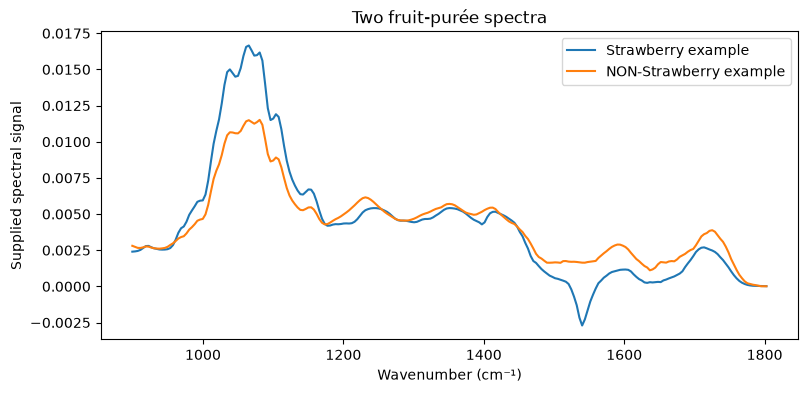

In [7]:
strawberry_id = labels.loc[labels == "Strawberry"].index[0]
other_id = labels.loc[labels == "NON-Strawberry"].index[0]
plt.figure(figsize=(9, 4))
plt.plot(spectra.columns, spectra.loc[strawberry_id], label="Strawberry example")
plt.plot(spectra.columns, spectra.loc[other_id], label="NON-Strawberry example")
plt.xlabel("Wavenumber (cm⁻¹)")
plt.ylabel("Supplied spectral signal")
plt.title("Two fruit-purée spectra")
plt.legend()
plt.show()

## 2. Describe each spectrum with eight numbers

Instead of giving the model all 235 signals, we divide the spectrum into
eight fixed windows and take the average signal in each window. These
eight averages become our new features, B1 to B8. For example, B1 averages
the signal between 899 and 1012 cm⁻¹. It is not a sugar concentration.

Each line below selects one range with `loc` and averages it for every
sample with `mean(axis=1)`. `head()` shows five rows; `round(4)` rounds
only the display. The original spectra remain available in `spectra`.

In [8]:
features = pd.DataFrame(index=spectra.index)
features["B1"] = spectra.loc[:, 899:1012].mean(axis=1)
features["B2"] = spectra.loc[:, 1012:1125].mean(axis=1)
features["B3"] = spectra.loc[:, 1125:1238].mean(axis=1)
features["B4"] = spectra.loc[:, 1238:1351].mean(axis=1)
features["B5"] = spectra.loc[:, 1351:1464].mean(axis=1)
features["B6"] = spectra.loc[:, 1464:1577].mean(axis=1)
features["B7"] = spectra.loc[:, 1577:1690].mean(axis=1)
features["B8"] = spectra.loc[:, 1690:1803].mean(axis=1)
features.head().round(4)

,B1,B2,B3,B4,B5,B6,B7,B8
1,0.0035,0.0097,0.0052,0.0051,0.0049,0.0019,0.0020,0.0019
2,0.0046,0.0149,0.0052,0.0043,0.0047,0.0006,-0.0003,0.0002
3,0.0041,0.0098,0.0050,0.0048,0.0047,0.0019,0.0022,0.0017
4,0.0037,0.0107,0.0055,0.0052,0.0045,0.0009,0.0015,0.0022
5,0.0038,0.0104,0.0057,0.0053,0.0044,0.0008,0.0012,0.0024


Draw the same two samples again, now using only their eight window means.
Each point represents one window's average. Compare these lines with the
original spectra: broad patterns remain, while individual peaks are lost.
The models below receive these eight values, not the original 235 signals.

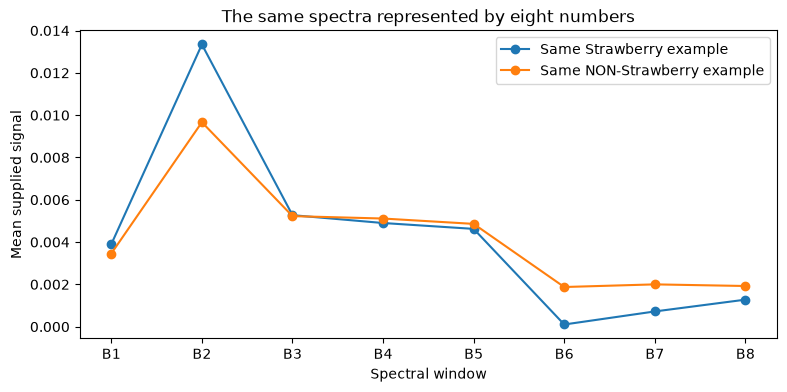

In [9]:
plt.figure(figsize=(9, 4))
plt.plot(features.columns, features.loc[strawberry_id], marker="o", label="Same Strawberry example")
plt.plot(features.columns, features.loc[other_id], marker="o", label="Same NON-Strawberry example")
plt.xlabel("Spectral window")
plt.ylabel("Mean supplied signal")
plt.title("The same spectra represented by eight numbers")
plt.legend()
plt.show()

### Stop and explain 1

What does one row of the feature table represent? What does the value in
B1 describe, and why is it not a sugar concentration?

Your answer:

Write your answer here in words.

## 3. Choose the strawberry reference group

First keep 20% of the samples aside for checking. This is the same split as
in Foundations: 784 training samples and 197 test samples. `random_state=42`
makes the split repeatable; `stratify=labels` keeps similar class proportions.

In the code, X means the eight feature columns and y means the
recorded labels. The endings `_train` and `_test` tell us
which sample group a table belongs to.

We return to the full 784-sample training group from Foundations,
including the samples set aside for validation in Evaluation.
Here the detector and its flagging setting are chosen in advance;
we are not using a validation set to compare alternatives.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.20, random_state=42, stratify=labels
)
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 784
Test samples: 197


From the training group, keep only the samples labelled Strawberry.
`loc` selects rows; `==` asks whether a label matches. These 280 samples
become the detector's reference for usual strawberry measurements.

We use the training labels to choose this reference group. We do not teach
the detector examples of NON-Strawberry. The test labels will be used only
to review its flags, after the detector and its setting are fixed.

In [11]:
authentic_training = X_train.loc[y_train == "Strawberry"]
print("Strawberry reference samples:", len(authentic_training))

Strawberry reference samples: 280


### Stop and explain 2

Why do we use only labelled Strawberry samples as the reference?
What would change if we included every kind of fruit purée?

Your answer:

Write your answer here in words.

## 4. Teach one outlier detector

We use an isolation forest. It makes many random questions about the
eight features. Unusual measurements can often be separated from most
reference samples with fewer questions. The forest combines this
information to flag unusual measurements. Evaluation's random forest
learned to predict class labels; this forest does a different job.

The first line creates the detector; `fit` teaches it from the strawberry
reference features. Unlike the classifiers in the earlier practicals,
this `fit` does not receive a column of class labels.

The setting `contamination=0.05` places a flagging boundary so that about
5% of the training reference samples are flagged. This is a teaching
choice fixed in advance. It does not mean that 5% of the purées are
adulterated, nor that 5% of future samples must be flagged. Keep it unchanged.

In [12]:
detector = IsolationForest(contamination=0.05, random_state=42)
detector.fit(authentic_training)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.05
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


### Stop and explain 3

Does the setting 0.05 tell us how many purées are adulterated?
Must exactly 5% of the test samples be flagged? Explain.

Your answer:

Write your answer here in words.

## 5. Flag the samples kept aside

`predict` checks the 197 test samples without using their labels. The
detector returns `-1` for unusual measurements and `1` for the rest.
`== -1` turns this into a simple flag: True means flagged and
False means not flagged. The table keeps the original row numbers.

In [13]:
flags = detector.predict(X_test) == -1
review = pd.DataFrame({"Flagged": flags}, index=X_test.index)
print("Samples checked:", len(review))
print("Flagged for follow-up:", review["Flagged"].sum())
review.head()

Samples checked: 197
Flagged for follow-up: 90


,Flagged
553,False
940,True
452,False
76,False
155,True


### Look at one flagged measurement

This cell selects the first flagged row in our test table. It compares
its eight features with the average of the training strawberry samples.
`mean()` gives one average per feature; `plot` draws the lines.

The line joins eight window means, rather than showing a full spectrum.
The strawberry average is a visual guide, not a pass/fail limit. The
detector uses the reference samples' variation across all eight features.
This one example does not represent every flagged sample.

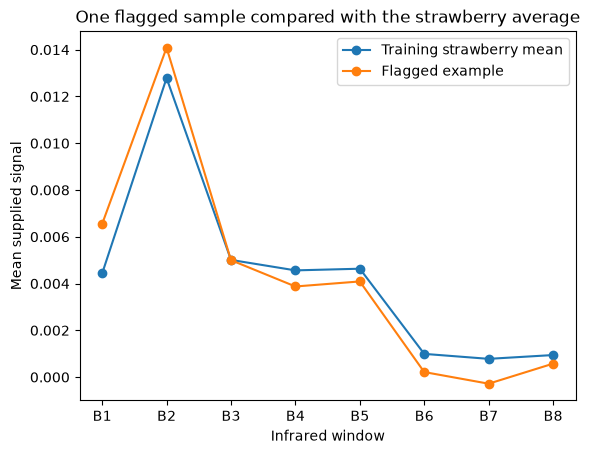

Example row: 940


In [14]:
example_id = review.loc[review["Flagged"]].index[0]
authentic_training.mean().plot(label="Training strawberry mean", marker="o")
X_test.loc[example_id].plot(label="Flagged example", marker="o")
plt.title("One flagged sample compared with the strawberry average")
plt.xlabel("Infrared window")
plt.ylabel("Mean supplied signal")
plt.legend()
plt.show()
print("Example row:", example_id)

### Stop and explain 4

In which windows does this example differ most visibly from the strawberry
average? Give one possible laboratory explanation for unusual measurements,
and one check you would make before rejecting the product.

Your answer:

Write your answer here in words.

## 6. Reveal the reference labels

Now add the known test labels to our review table. They did not enter the
detector's training or its flagging boundary. `crosstab` counts how often
each label occurs with and without a flag. Read a row across: its two
numbers add up to the number of test samples with that reference label.

NON-Strawberry includes other fruits and adulterated strawberry mixtures;
this file does not tell us which is which for individual samples.

As with the mistake tables in Foundations and Evaluation, rows show
reference labels. Here the columns mean Not flagged and Flagged,
rather than predicted classes. A flag requests review; it is not
a NON-Strawberry prediction. There is no classification accuracy here.

In [15]:
review["Reference"] = y_test
counts = pd.crosstab(review["Reference"], review["Flagged"])
counts = counts.rename(columns={False: "Not flagged", True: "Flagged"})
counts

Flagged,Not flagged,Flagged
Reference,,
NON-Strawberry,38,89
Strawberry,69,1


The next cell draws these same counts as bars. Taller bars mean more samples.
The two reference groups have different sizes, so compare each flagged
count with the total in its own row of the table above.

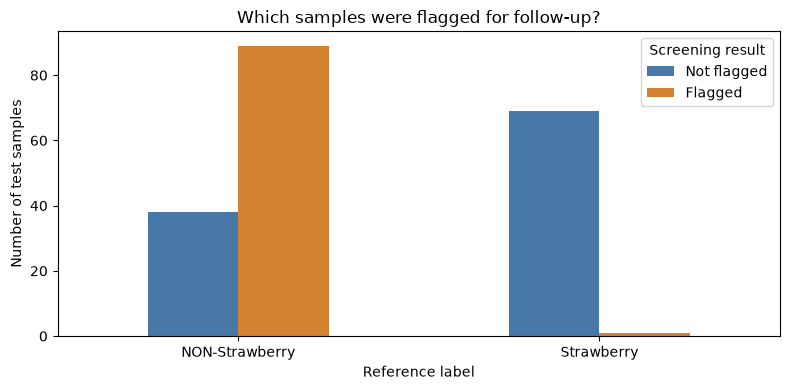

In [16]:
counts.plot.bar(color=["#4878A8", "#D58232"], rot=0, figsize=(8, 4))
plt.ylabel("Number of test samples")
plt.xlabel("Reference label")
plt.title("Which samples were flagged for follow-up?")
plt.legend(title="Screening result")
plt.tight_layout()
plt.show()

### Stop and explain 5

How many labelled Strawberry samples were flagged?
How many NON-Strawberry samples escaped a flag? Give one laboratory
consequence of each outcome. Use the table to support your answer.

Your answer:

Write your answer here in words.

## 7. Decide what the laboratory should do

A flag can prioritise follow-up work. An authentic sample can be unusual;
a different fruit or mixture can resemble the reference measurements.
Not flagged does not certify purity. This screen cannot identify an
adulterant or measure its amount.

The test group was also used in the earlier practicals. Reusing it here
is a classroom demonstration, not new independent validation. The file
lacks supplier, batch and physical-specimen IDs. A laboratory would need
independent samples and a justified flagging boundary before routine use.

### Stop and explain 6

The manager proposes releasing every unflagged sample and discarding every
flagged one. Write two or three sentences explaining what you recommend
instead, using one result from this practical.

Your answer:

Write your answer here in words.

## Data and reuse

The dataset contains measured infrared spectra of fruit purées. The
original file has 983 spectra; 981 remain after excluding the conflicting
pair. NON-Strawberry includes other fruits and adulterated mixtures.
The file does not give separate adulterant, supplier or replicate IDs.
These exercises cannot establish product purity or identify an adulterant.

- Holland, Kemsley and Wilson (1998), *Use of Fourier transform infrared
  spectroscopy and partial least squares regression for the detection of
  adulteration of strawberry purées*.
  [Original study](https://research-portal.uea.ac.uk/en/publications/use-of-fourier-transform-infrared-spectroscopy-and-partial-least-/).
- Shu, Tang, Zhang and Zheng (2019),
  [dataset deposition](https://doi.org/10.17632/frrv2yd9rg.1), version 1.
  Data licence: [CC BY-NC 3.0](https://creativecommons.org/licenses/by-nc/3.0/).
  The data licence is separate from the course-code licence.

The fixed spectral windows are teaching summaries, not selected chemical
markers. This exercise does not reproduce the original paper's analysis.

Detector reference: [scikit-learn isolation forest documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html).